# Boston 311 Crew Planner: demo notebook

DADS5250 Generative AI in Practice, Module 7 Hackathon, Group 09: John Baldwin, Nicholas Maar, Adam Jaroudi, Andrew Lai.

**What this notebook does.** It runs the whole product end to end:

1. **Data.** Real 2023 and 2024 Boston 311 requests, fetched from data.boston.gov's API and reduced to small committed tables.
2. **Forecast.** Monthly 2025 demand per department (seasonal naive).
3. **Staffing plan.** A month-by-month hire / release / seasonal-crew plan, made on a *planning* workload, frozen, then scored on a separate *evaluation* workload with a daily queue simulator.
4. **Sensitivity.** The frozen plan and the fixed-crew baseline replayed on +20%, -20%, and snowstorm workloads.
5. **Intake assistant.** A LangGraph agent with retrieval (RAG) and structured output that routes plain-language messages to an official request type and department, with accuracy on a 40-message test set.
6. **Other consideration.** Neighborhood equity in historical response times.

**Modes.** `MODE = "offline"` (the default) replays recorded model answers, so the notebook runs with **no API key and no network**. `MODE = "live"` calls OpenAI (`gpt-6.1-sol`) for anything not yet recorded and needs `OPENAI_API_KEY` in `.env`. Offline results are the recorded live answers, not new model calls.

This is a demonstration. It never submits a request to the city and never promises a completion date.

## Summary

**The problem.** Boston's 311 system takes residents' service requests and sends them to city departments, whose crews close them. The project asks for a month-by-month 2025 crew plan for four departments (Public Works, Transportation, Parks & Recreation, and Inspectional Services). The plan must balance cost, timely service (Transportation especially), and flexibility under the challenge's hiring, release, and seasonal-crew rules. The project also asks for a GenAI intake assistant that turns a resident's plain-language message into an official request type and department.

**Approach.**
* Forecast 2025 monthly demand per department from 2023 and 2024 data.
* Turn the forecast into individual synthetic requests, with deadlines drawn from each type's history.
* A heuristic planner decides hires, releases, and Parks seasonal crews month by month, looking only at a *planning* workload. The plan is then frozen and scored by a daily queue simulator on a separate *evaluation* workload, against keeping January's crews all year.
* The intake assistant retrieves candidate official types, has the model pick one with structured output, and lets code decide whether to route, ask one clarifying question, or send the request to a person (triage).

**Results** on the base evaluation workload, which the planner never saw:

| | Frozen plan | January crews all year |
|---|---|---|
| Total 2025 cost (crews + severance + penalties) | **$16.39M** | $19.47M |
| Share of requests due in 2025 closed on time | **89.5%** | 22.4% |
| Requests still open on December 31 | 1,441 | 27,579 |

* The plan hires 20 Public Works, 8 Transportation, 9 Inspectional Services, and 1 Parks crew, all ordered by August, and releases none.
* Parks covers its April-to-October peak with 42 seasonal crew-months and reaches 95.4% on time for $1.86M.
* Transportation goes from 12.1% to 88.7% on time, and its cost falls from $6.79M to $2.91M because penalties shrink.
* The intake assistant makes the correct decision (route, triage, or reject) on 40 of 40 test messages, picks the correct type on 33 of 34, and is right on 28 of 29 auto-routes (96.6% precision).

Every number here is computed in the cells below and saved in `outputs/`.

## Challenge assumptions and modeling choices

The project page fixes these assumptions. They make plans comparable within the challenge; they are not estimates of Boston's real operations.

| Rule | Value |
|---|---|
| Service days per crew-month | 21 |
| Hiring | 1 month of hiring and training before a new crew starts |
| Release | 1 month notice; costs 25% of the crew's annual cost |
| Seasonal crews | Parks only, April to October, 1.3x monthly crew cost, no training delay, no release cost |
| Starting backlog | Zero on January 1, 2025 |
| Overdue | $20 when a request is not closed by its target date |
| Long overdue | Additional $100 if still open 30 days after its target date |

| Department | 2024 requests | On time 2024 | Capacity per crew-day | Annual cost per crew | Crews in January 2025 |
|---|---|---|---|---|---|
| Public Works (PWDx) | 157,610 | 90% | 12 | $130,000 | 50 |
| Transportation (BTDT) | 81,447 | 50% | 15 | $110,000 | 18 |
| Parks & Recreation (PARK) | 18,736 | 93% | 6 | $120,000 | 10 |
| Inspectional Services (ISD) | 18,624 | 72% | 4 | $140,000 | 16 |

With January's crews held all year, every department has less annual capacity than its 2024 demand (coverage 81% to 96%). That is why a dynamic plan is compared against fixed staffing.

**Modeling choices** (full rules in `docs/architecture.md`, sections 5.3, 5.4, and 11):
* **Calendar:** 21 service days a month, the first 21 weekdays plus the earliest Saturdays when a month has fewer. Holidays are ignored. This calendar is synthetic.
* **Deadlines:** a request closed on its target date is on time. $20 is charged at the end of the target day if it is still open, and $100 more thirty days later.
* **Paid training:** a new crew is paid during its training month.
* **No-target requests** use crew capacity but carry no penalty and are left out of on-time rates.
* **Costs count within 2025 only.** No hire is ordered after October and no release notice is given after August. Effects past December 31 are disclosed, not charged.

In [1]:
MODE = "offline"   # "offline" (no key needed) or "live" (needs OPENAI_API_KEY in .env)

# This notebook must run on the project's own Python environment, where the
# boston311 package is installed. If it is not, stop with a clear message
# instead of a confusing traceback.
import sys
try:
    import boston311
except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "The boston311 package is not installed in this kernel's Python (" + sys.executable + ").\n"
        "Fix: in Jupyter choose Kernel > Change Kernel > 'Python (boston311)'. If that kernel is missing, "
        "follow README > Setup (create .venv, install, then register the kernel with "
        "'python -m ipykernel install --user --name boston311')."
    ) from None

import pandas as pd
import matplotlib.pyplot as plt
from boston311 import config, data, forecast, workload, staffing, evaluate, equity, manifest
from boston311.agent import IntakeAssistant

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("mode:", MODE, "| model:", config.LLM_MODEL, "| prompt:", config.PROMPT_VERSION, "| catalog:", config.CATALOG_VERSION)

mode: offline | model: gpt-6.1-sol | prompt: classify-v2 | catalog: catalog-v2


## 1. Data and reconciliation

The raw files (about 180 MB each) are downloaded once by `python scripts/build_data.py` through the CKAN API of data.boston.gov and checked against the checksum the city publishes. They are not needed to run this notebook: the small count tables in `data/processed/` are committed.

Our 2024 counts for the four departments must match the project page exactly.

In [2]:
recon = data.load_reconciliation()
display(pd.DataFrame(recon["page_check_2024"]).T)
display(pd.DataFrame(recon["by_year"]).T[["rows_read", "duplicates_removed", "out_of_scope_departments_excluded", "in_scope_rows", "target_classes"]])
display(pd.DataFrame(recon["sources"])[["year", "size_bytes", "md5", "last_modified"]])

,page,ours,match
PWDx,157610,157610,True
BTDT,81447,81447,True
PARK,18736,18736,True
ISD,18624,18624,True


,rows_read,duplicates_removed,out_of_scope_departments_excluded,in_scope_rows,target_classes
2023,307791,0,25545,282246,"{'valid': 231524, 'missing': 50722, 'invalid_o..."
2024,306756,0,30339,276417,"{'valid': 244996, 'missing': 31421, 'invalid_o..."


,year,size_bytes,md5,last_modified
0,2023,184129946,beb0947323226eb7d9a6abd2207e4635,2026-09-18T01:27:26.805931
1,2024,182147317,99da78a9b838728d35d52658b7011a15,2026-09-18T01:27:27.630670


**What the reconciliation shows.**
* Our 2024 counts match the project page exactly: 157,610 / 81,447 / 18,736 / 18,624. Neither year has duplicate case IDs.
* 11% of 2024 in-scope requests (31,421 of 276,417) have no target date. None has a target before its open date.
* Valid target windows run from 0 to 720 days. 55% of 2023 to 2024 Parks targets are a year or longer, which matters for the seasonal rule below.
* The city's `on_time` flag counts a request closed on its target date, but after the target time, as late. The simulator counts it as on time (calendar-date convention). Simulated on-time rates are therefore not directly comparable with the city's historical rates, which the assistant's replies use.

## 2. 2025 demand forecast

**Seasonal naive**: each 2025 month equals the same month of 2024. With only two years of history, a fancier model cannot be validated fairly, so the spec keeps the baseline. The backtest shows how the same method would have done one year earlier (predicting 2024 from 2023).

In [3]:
fc = forecast.forecast_2025()
display(fc.pivot(index="month", columns="department", values="forecast")[list(config.DEPT_CODES)])
display(forecast.backtest())

department,PWDx,BTDT,PARK,ISD
month,,,,
1,13582,5620,928,1491
2,11550,5954,794,1285
3,13092,7209,1291,1342
4,13998,7008,1519,1415
5,13333,7511,2029,1555
6,12917,7176,2881,1779
7,13915,6678,2640,1796
8,16398,6719,2143,2077
9,15912,7633,1587,1809


,department,forecast_total,actual_total,mape_pct,annual_bias_pct
0,PWDx,171268,157610,13.60,8.70
1,BTDT,75314,81447,7.60,-7.50
2,PARK,17541,18736,17.70,-6.40
3,ISD,18123,18624,13.30,-2.70


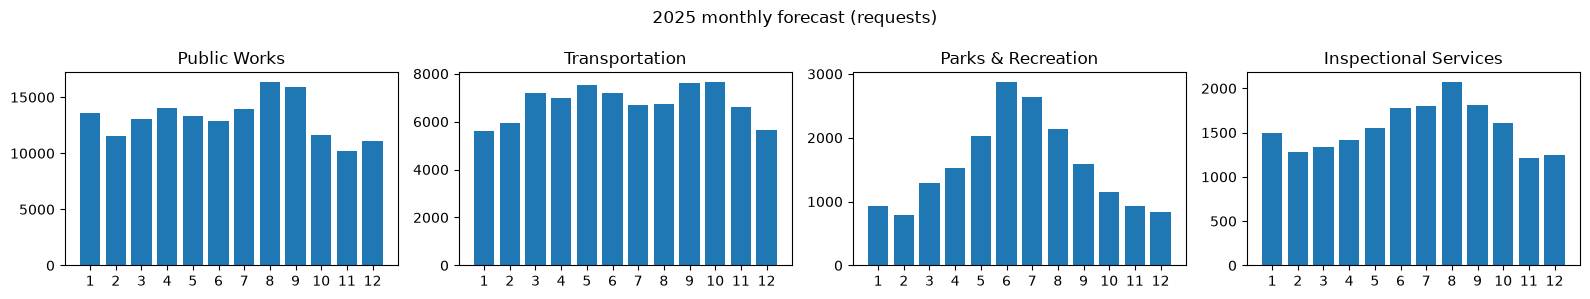

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, dept in zip(axes, config.DEPT_CODES):
    d = fc[fc.department == dept]
    ax.bar(d.month, d.forecast)
    ax.set_title(config.DEPARTMENTS[dept].name)
    ax.set_xticks(range(1, 13))
fig.suptitle("2025 monthly forecast (requests)")
plt.tight_layout(); plt.show()

**Backtest.** The same method predicting 2024 from 2023:

| Department | Mean absolute % error by month | Annual bias |
|---|---|---|
| PWDx | 13.6% | +8.7% |
| BTDT | 7.6% | -7.5% |
| PARK | 17.7% | -6.4% |
| ISD | 13.3% | -2.7% |

The ±20% sensitivity scenarios in section 6 bracket these errors.

## 3. Workloads

The simulator needs individual requests with deadlines, not just monthly totals. A **workload** is the full list of 2025 requests: arrival day, type, and target date.

* Arrival counts are deterministic: exact rounding of the forecast and the 2024 type mix.
* Target dates are drawn from 2023 to 2024 history with a seeded random generator.
* There are two independent streams. The **planning** workload is the only one the planner sees. The **base evaluation** workload scores the frozen plan.
* The +20%, -20%, and snowstorm workloads are built *from* the base evaluation workload, only adding or removing requests.

In [5]:
wl = workload.build_all_workloads(fc)
display(pd.DataFrame({name: {"requests": len(w.requests),
                             "with target date": int((w.requests.target_class == "valid").sum()),
                             "no target date": int((w.requests.target_class != "valid").sum())}
                      for name, w in wl.items()}).T)

,requests,with target date,no target date
planning,276417,244997,31420
base,276417,245000,31417
plus20,331701,294010,37691
minus20,221133,195884,25249
spike,278905,246832,32073


## 4. The frozen staffing plan

At the start of each month, using projections on the planning workload only:

* **Parks seasonal crews** (April to October): the fewest crews that keep the month's due requests at least **93% on time**, Parks' own 2024 rate. If 93% is impossible, they reach the best rate possible.
* **Hire** only if a shortage is projected in *both* of the next two months, and hire the smaller shortage. Hiring stops after October. Parks never starts a permanent crew in season.
* **Release** only if no hire was ordered and a five-month projection shows no more penalty events, no higher cost (severance counted), and no bigger backlog. Releases stop after August.

After December the decisions are frozen.

**Why these rules.**
* **Two months before hiring.** A hire costs a paid training month, and releasing it later costs three months of pay in severance. A crew used for k productive months therefore costs k + 4 months of pay, so a one-month spike is not worth a permanent crew.
* **Seasonal crews instead of in-season permanent hires at Parks.** A seasonal crew costs 1.3 months of pay per month used. For a new crew used k months and then released, seasonal is cheaper whenever 1.3k < k + 4, that is k < 13.3, which is longer than the 7-month season.
* **Three checks before a release.** Severance alone is three months of pay, and a release can shift work onto more expensive seasonal crews. The projection must show no extra penalty events, no extra cost, and no bigger backlog.

In [6]:
plan = staffing.make_plan(wl["planning"])
baseline = staffing.baseline_plan()
pf = plan.to_frame()
display(pf.pivot(index="month", columns="department", values=["regular_crews", "hires_ordered", "releases_noticed", "seasonal_crews"]))
for dept, dp in plan.departments.items():
    for line in dp.log:
        print(f"{dept}: {line}")

regular_crews               hires_ordered               releases_noticed               seasonal_crews              
department          BTDT ISD PARK PWDx          BTDT ISD PARK PWDx             BTDT ISD PARK PWDx           BTDT ISD PARK PWDx
month                                                                                                                         
1                     18  16   10   50             3   2    0    2                0   0    0    0              0   0    0    0
2                     21  18   10   52             2   0    1    0                0   0    0    0              0   0    0    0
3                     23  18   11   52             1   0    0    6                0   0    0    0              0   0    0    0
4                     24  18   11   58             1   1    0    0                0   0    0    0              0   0    1    0
5                     25  19   11   58             0   4    0    0                0   0    0    0              0   0    5    0
6                     25  23   11   58             0   0    0    0                0   0    0    0              0   0   12    0
7                     25  23   11   58             0   2    0   12                0   0    0    0              0   0    9    0
8                     25  25   11   70             1   0    0    0                0   0    0    0              0   0   13    0
9                     26  25   11   70             0   0    0    0                0   0    0    0              0   0    2    0
10                    26  25   11   70             0   0    0    0                0   0    0    0              0   0    0    0
11                    26  25   11   70             0   0    0    0                0   0    0    0              0   0    0    0
12                    26  25   11   70             0   0    0    0                0   0    0    0              0   0    0    0

PWDx: month 1: projected shortage 2 crews in month 2 and 4 in month 3; ordered 2 hire(s), productive from month 2
PWDx: month 3: projected shortage 6 crews in month 4 and 7 in month 5; ordered 6 hire(s), productive from month 4
PWDx: month 7: projected shortage 12 crews in month 8 and 17 in month 9; ordered 12 hire(s), productive from month 8
BTDT: month 1: projected shortage 3 crews in month 2 and 8 in month 3; ordered 3 hire(s), productive from month 2
BTDT: month 2: projected shortage 2 crews in month 3 and 4 in month 4; ordered 2 hire(s), productive from month 3
BTDT: month 3: projected shortage 1 crews in month 4 and 3 in month 5; ordered 1 hire(s), productive from month 4
BTDT: month 4: projected shortage 2 crews in month 5 and 1 in month 6; ordered 1 hire(s), productive from month 5
BTDT: month 8: projected shortage 1 crews in month 9 and 2 in month 10; ordered 1 hire(s), productive from month 9
PARK: month 2: projected shortage 1 crews in month 3 and 1 in month 4; ordered 1 hir

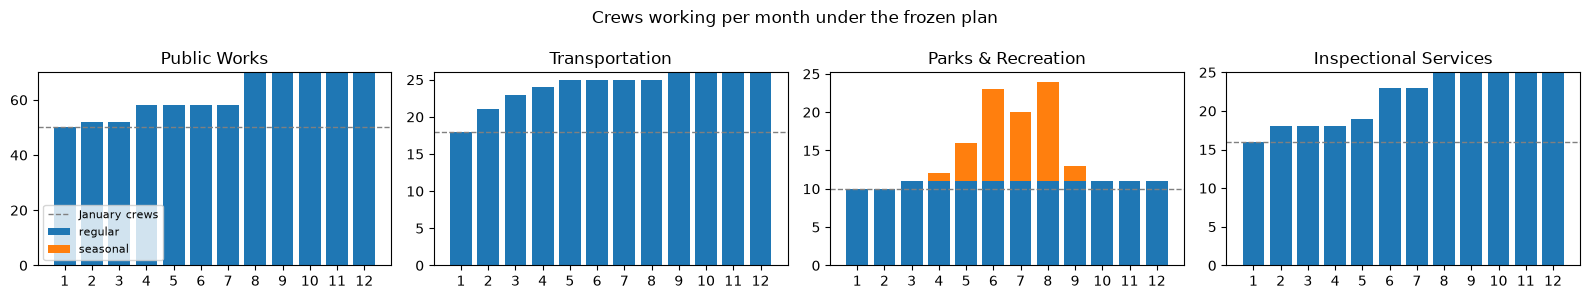

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, dept in zip(axes, config.DEPT_CODES):
    d = pf[pf.department == dept]
    ax.bar(d.month, d.regular_crews, label="regular")
    ax.bar(d.month, d.seasonal_crews, bottom=d.regular_crews, label="seasonal")
    ax.axhline(config.DEPARTMENTS[dept].start_crews, color="grey", ls="--", lw=1, label="January crews")
    ax.set_title(config.DEPARTMENTS[dept].name); ax.set_xticks(range(1, 13))
axes[0].legend(fontsize=8)
fig.suptitle("Crews working per month under the frozen plan")
plt.tight_layout(); plt.show()

**What the plan does.**
* It hires 20 Public Works, 8 Transportation, 9 Inspectional Services, and 1 Parks crew. The last hire is ordered in August.
* Parks adds 42 seasonal crew-months from April to October.
* No crew is released. Demand rises from spring to an August and September peak. In August, the last month a notice is allowed, the projection still sees that peak, so no release passes the checks.
* The price of the "no notices after August" rule, combined with 25% severance, is idle capacity late in the year. Public Works runs at 58% to 69% utilization from October to December, and Inspectional Services at 59% to 60% in November and December.

### Why a 93% service floor for Parks seasonal crews?

Service matters as much as cost, so the target comes first and cost decides only how to meet it. The table below re-makes the whole plan for a range of monthly targets and scores Parks on the base evaluation workload (about 20 seconds).

* Up to the 93% floor, extra service is cheap.
* Above it, each extra on-time point costs far more.
* "Every avoidable miss" is the spec's original rule, equivalent to a 100% target.

A cost-only rule does not reflect that: the $20 overdue penalty is small next to a $13,000 seasonal crew-month, so such a rule accepts most misses. Two were tested and rejected:
* **"Add a crew only while it saves more in penalties than it costs."** No single crew ever saves that much, so the rule bought no seasonal crews. The backlog grew all season, the hiring rule then ordered 27 permanent crews in October, and Parks came to $2.57M with 29% on time.
* **"Minimize seasonal cost plus penalties."** Parks came to $1.82M with 32% on time.

,rule,parks_total_cost,parks_on_time_rate,seasonal_crew_months,permanent_hires,cost_per_extra_point,chosen
0,baseline (January crews),"1,746,340.00",0.21,0,0,NaN,False
1,floor 50%,"1,779,200.00",0.73,33,1,634.29,False
2,floor 70%,"1,791,900.00",0.82,35,1,"1,427.37",False
3,floor 80%,"1,836,300.00",0.87,39,1,"8,732.78",False
4,floor 85%,"1,806,480.00",0.90,37,1,"-11,668.83",False
5,floor 90%,"1,839,380.00",0.94,40,1,"8,062.12",False
6,floor 93%,"1,862,860.00",0.95,42,1,"13,927.74",True
7,floor 95%,"1,951,920.00",0.97,49,1,"68,622.11",False
8,floor 97%,"2,127,200.00",0.97,71,0,"363,900.76",False
9,every avoidable miss,"2,438,240.00",0.98,95,0,"484,315.20",False


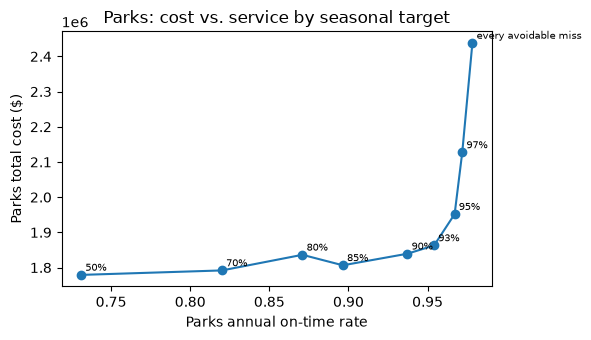

In [8]:
frontier = staffing.seasonal_frontier(wl)
display(frontier)
ax = frontier.iloc[1:].plot(x="parks_on_time_rate", y="parks_total_cost", marker="o", legend=False, figsize=(6, 3.5))
for _, r in frontier.iloc[1:].iterrows():
    ax.annotate(r["rule"].replace("floor ", ""), (r["parks_on_time_rate"], r["parks_total_cost"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Parks annual on-time rate"); ax.set_ylabel("Parks total cost ($)"); ax.set_title("Parks: cost vs. service by seasonal target")
plt.tight_layout(); plt.show()

**Reading the frontier.**
* Going from January crews (21.3% on time) to the 93% floor (95.4%) costs Parks $117K more.
* Beyond 93%, each extra on-time point costs $69K to $484K.
* Against the original rule, the 93% floor gives up 2.4 on-time points and saves $575K.
* Neighbouring targets can swap order on cost (the 85% floor is cheaper than 80%), because the whole plan is re-made for each target and later hiring reacts to the seasonal choice.
* The frontier depends on the challenge's assumed costs and penalties. 93% is a policy choice, not an optimum.

## 5. Scoring: frozen plan vs. fixed January crews

Both plans are scored by the same daily simulator on the same **base evaluation** workload, which the planner never saw. Each scenario produces 48 staffing rows (4 departments x 12 months). Full reconciliation checks run on every plan and scenario: request flow, workforce, penalties, and costs.

In [9]:
scored, summaries = {}, []
for p in (plan, baseline):
    for scenario in config.SCENARIOS:
        rows, year_ends = staffing.score_plan(p, wl[scenario], scenario)
        assert staffing.reconciliation_failures(rows, p, wl[scenario]) == [], (p.name, scenario)
        scored[(p.name, scenario)] = (rows, year_ends)
        summaries.append(staffing.summarize(rows, year_ends))
summary = pd.concat(summaries, ignore_index=True)
print("Reconciliation checks passed for all", len(scored), "plan x scenario combinations.")
base_cmp = summary[summary.scenario == "base"].set_index(["department", "plan"])[["staff_cost", "penalty_cost", "total_cost", "overdue_events", "long_overdue_events", "on_time_rate", "open_dec31"]]
display(base_cmp.unstack("plan"))

Reconciliation checks passed for all 8 plan x scenario combinations.


staff_cost               penalty_cost               total_cost               overdue_events           long_overdue_events           on_time_rate           open_dec31          
plan            baseline     heuristic     baseline  heuristic      baseline     heuristic       baseline heuristic            baseline heuristic     baseline heuristic   baseline heuristic
department                                                                                                                                                                                   
ALL        11,920,000.00 15,916,000.00 7,554,180.00 478,440.00 19,474,180.00 16,394,440.00         176829     23922               40176         0         0.22      0.90      27579      1441
BTDT        1,980,000.00  2,731,666.67 4,814,240.00 177,680.00  6,794,240.00  2,909,346.67          69367      8884               34269         0         0.12      0.89      13865       483
ISD         2,240,000.00  3,138,333.33   288,560.00  18,580.00  2,528,560.00  3,156,913.33           6328       929                1620         0         0.57      0.94       2496        50
PARK        1,200,000.00  1,856,000.00   546,340.00   6,860.00  1,746,340.00  1,862,860.00           5882       343                4287         0         0.21      0.95       4434        42
PWDx        6,500,000.00  8,190,000.00 1,905,040.00 275,320.00  8,405,040.00  8,465,320.00          95252     13766                   0         0         0.25      0.89       6784       866

**Frozen plan vs. January crews (base workload).**
* Total cost is $16.39M against $19.47M. The plan spends $4.00M more on crews ($15.92M against $11.92M) but $7.08M less on penalties ($0.48M against $7.55M).
* 89.5% of requests due in 2025 close on time, against 22.4%, and 1,441 requests are open on December 31, against 27,579. The plan incurs no $100 long-overdue events.
* The plan's on-time rates are 89.1% for Public Works, 88.7% for Transportation, 95.4% for Parks, and 93.7% for Inspectional Services.
* Transportation, which the project page singles out, improves most: from 12.1% to 88.7% on time, while its total cost falls from $6.79M to $2.91M.

### Dynamic staffing table (base scenario, frozen plan)

One row per department and month. Events (hires, closures, penalties) are kept separate from month-end inventory (open requests by status).

In [10]:
rows, _ = scored[("heuristic", "base")]
display(rows[["department", "month", "regular_crews", "hires_ordered", "releases_noticed", "seasonal_crews", "capacity",
              "arrivals", "closed", "overdue_events", "long_overdue_events", "open_end", "total_cost"]])

,department,month,regular_crews,hires_ordered,releases_noticed,seasonal_crews,capacity,arrivals,closed,overdue_events,long_overdue_events,open_end,total_cost
0,PWDx,1,50,2,0,0,12600,13582,12226,1683,0,1356,"596,993.33"
1,PWDx,2,52,0,0,0,13104,11550,12906,2366,0,0,"610,653.33"
2,PWDx,3,52,6,0,0,13104,13092,12506,818,0,586,"644,693.33"
3,PWDx,4,58,0,0,0,14616,13998,13735,810,0,849,"644,533.33"
4,PWDx,5,58,0,0,0,14616,13333,13363,1099,0,819,"650,313.33"
5,PWDx,6,58,0,0,0,14616,12917,13199,1055,0,537,"649,433.33"
6,PWDx,7,58,12,0,0,14616,13915,13260,910,0,1192,"776,533.33"
7,PWDx,8,70,0,0,0,17640,16398,16574,2548,0,1016,"809,293.33"
8,PWDx,9,70,0,0,0,17640,15912,15726,1033,0,1202,"778,993.33"
9,PWDx,10,70,0,0,0,17640,11639,12130,582,0,711,"769,973.33"


## 6. Sensitivity analysis

The *frozen* plan (no re-planning) and the baseline replayed on demand 20% higher, 20% lower, and a snowstorm: Public Works arrivals tripled on February 10 to 12, 2025.

staff_cost                penalty_cost                 total_cost               on_time_rate           open_dec31          
plan          baseline     heuristic      baseline    heuristic      baseline     heuristic     baseline heuristic   baseline heuristic
scenario                                                                                                                               
base     11,920,000.00 15,916,000.00  7,554,180.00   478,440.00 19,474,180.00 16,394,440.00         0.22      0.90      27579      1441
plus20   11,920,000.00 15,916,000.00 21,284,560.00 4,936,100.00 33,204,560.00 20,852,100.00         0.08      0.12      81746     11900
minus20  11,920,000.00 15,916,000.00  1,171,560.00   200,320.00 13,091,560.00 16,116,320.00         0.75      0.95       2570       925
spike    11,920,000.00 15,916,000.00  8,438,820.00   840,640.00 20,358,820.00 16,756,640.00         0.16      0.82      30067      1441

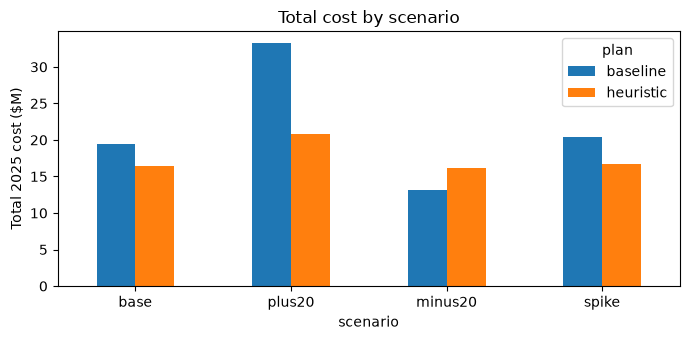

In [11]:
tot = summary[summary.department == "ALL"].set_index(["scenario", "plan"])[["staff_cost", "penalty_cost", "total_cost", "on_time_rate", "open_dec31"]]
display(tot.unstack("plan").reindex(list(config.SCENARIOS)))
ax = (summary[summary.department == "ALL"].pivot(index="scenario", columns="plan", values="total_cost").reindex(list(config.SCENARIOS)) / 1e6).plot.bar(rot=0, figsize=(7, 3.5))
ax.set_ylabel("Total 2025 cost ($M)"); ax.set_title("Total cost by scenario"); plt.tight_layout(); plt.show()

**What the scenarios show.** The frozen plan is replayed without re-planning.
* **Demand +20%:** the plan cannot keep up. Backlogs push most short-deadline requests past target (12.2% on time, 11,900 open on December 31), although its cost of $20.85M stays $12.35M below the baseline's $33.20M.
* **Demand -20%:** the plan is overstaffed (94.5% on time for $16.12M). Keeping January's crews would have been $3.02M cheaper, at 75.4% on time.
* **Snowstorm:** the extra Public Works volume lowers its on-time rate for the year from 89.1% to 75.2%. Overall, 81.7% of requests close on time, and the total cost rises by only $0.36M, to $16.76M.
* Both demand directions argue for reactive re-planning, which was not built (stretch).

### Year-end disclosures (base scenario, frozen plan)

Costs count only within 2025. Requests still open on December 31 are classified, not silently dropped.

In [12]:
_, ye = scored[("heuristic", "base")]
display(pd.DataFrame([y.__dict__ for y in ye]))

,department,costs_accrued,open_overdue_charged,open_long_overdue_charged,long_threshold_in_2026,not_yet_due,open_no_target,hires_ordered_effective_2026,notices_effective_2026,due_in_2025,on_time_rate
0,PWDx,"8,465,320.00",176,0,176,622,68,0,0,126732,0.89
1,BTDT,"2,909,346.67",160,0,160,320,3,0,0,78890,0.89
2,PARK,"1,862,860.00",1,0,1,41,0,0,0,7474,0.95
3,ISD,"3,156,913.33",0,0,0,50,0,0,0,14808,0.94


## 7. The intake assistant

Flow: **retrieve** candidate official types (TF-IDF over names, descriptions, and reviewed aliases) -> **classify** once with structured output -> **validate in code** -> **route**, **clarify** (one LangGraph interrupt), or **triage**. The model only proposes a type; code assigns the department and queue from reviewed mappings.

Two-tier routing: a type routes to its **department** when one in-scope department handled at least 90% of its handled requests. It names an **exact queue** only when one queue handled at least 90%; otherwise the reply says the queue is assigned by location or by the department.

**Coverage after the catalog review.** 124 of the 163 official types have an approved department mapping and can auto-route, and 83 of those also name an exact queue. Eight internal or undefined types were rejected and 31 never met the rule; those go to triage. Potholes are among the 31: Public Works handles 84% of them and the Water and Sewer Commission 14%, so a pothole report is classified correctly but sent to a person.

In [13]:
assistant = IntakeAssistant(mode=MODE)
demo = ["A car is parked in front of my driveway and I can't get out.",
        "dead raccoon in the middle of the road on Adams St",
        "Huge pothole on Tremont St near the Park Street T stop. It almost blew out my tire.",
        "Someone broke into my car last night and stole my laptop.",
        ""]
for msg in demo:
    r = assistant.run(msg)
    print(f"MESSAGE: {msg!r}\nDECISION: {r.decision.value}\n{r.response_text}\n" + "-" * 80)

MESSAGE: "A car is parked in front of my driveway and I can't get out."
DECISION: ROUTE
This looks like a "Parking Enforcement" request, handled by Transportation. It would go to the BTDT_Parking Enforcement queue. Historically (2023-2024), 57% of these requests with a target date were closed on time (based on 119,807 requests); closed requests took a median of 0.7 days to close (based on 104,735 closed requests). This is past performance, not a promise.

This is a demonstration assistant: nothing has been submitted to the City of Boston, and no completion date is promised.
--------------------------------------------------------------------------------


MESSAGE: 'dead raccoon in the middle of the road on Adams St'
DECISION: ROUTE
This looks like a "Pick up Dead Animal" request, handled by Public Works. The exact queue is assigned by location (the district or region of the address). Historically (2023-2024), 98% of these requests with a target date were closed on time (based on 13,745 requests); closed requests took a median of 0.1 days to close (based on 13,744 closed requests). This is past performance, not a promise.

This is a demonstration assistant: nothing has been submitted to the City of Boston, and no completion date is promised.
--------------------------------------------------------------------------------
MESSAGE: 'Huge pothole on Tremont St near the Park Street T stop. It almost blew out my tire.'
DECISION: TRIAGE
I could not route this automatically ("Request for Pothole Repair" is not handled consistently by one department (most often Public Works), so a person needs to route it). A staff member would review it.

This

In [14]:
# A clarification round trip: the assistant asks one question, then routes.
turn = assistant.submit("There's a light out.")
print("ASSISTANT ASKS:", turn.question)
turn = assistant.answer(turn.thread_id, "It's a street light on the sidewalk in front of my house on Dorchester Ave.")
print("DECISION:", turn.result.decision.value)
print(turn.result.response_text)

ASSISTANT ASKS: Is it a streetlight, a traffic signal, or a light in a park?
DECISION: ROUTE
This looks like a "Street Light Outages" request, handled by Public Works. The department assigns the exact queue. Historically (2023-2024), 56% of these requests with a target date were closed on time (based on 8,416 requests); closed requests took a median of 4.5 days to close (based on 8,013 closed requests). This is past performance, not a promise.

This is a demonstration assistant: nothing has been submitted to the City of Boston, and no completion date is promised.


### Accuracy on the dev and test sets (demonstration evaluation)

* **Test set:** 40 messages covering clear requests, paraphrases, confusions, missing context, multiple issues, out-of-scope requests, and empty input. It was never used for tuning.
* **Dev set:** 18 separate messages, used to tune the prompt and the retrieval gate.
* Both sets are pending team review.

In [15]:
results = {name: evaluate.run_set(assistant, evaluate.load_set(name)) for name in ("dev", "test")}
display(pd.concat({name: evaluate.metrics_table(df).set_index("metric") for name, df in results.items()}, axis=1))
display(evaluate.retrieval_recall(evaluate.load_set("dev")))

dev                  test              
                                            correct total percent correct total percent
metric                                                                                 
decision accuracy                                18    18  100.00      40    40  100.00
type accuracy                                    15    15  100.00      33    34   97.10
department accuracy                              12    13   92.30      30    31   96.80
queue accuracy (exact queues)                     8     8  100.00      19    20   95.00
queue accuracy (location/department labels)       4     5   80.00      10    11   90.90
auto-route precision                             12    12  100.00      29    30   96.70
auto-route coverage                              12    13   92.30      30    31   96.80
clarification rate                                3    18   16.70       8    40   20.00
triage rate                                       5    18   27.80       8    40   20.00

,aliases,k,found,items,recall_pct
0,True,8,15,15,100.00
1,False,8,7,15,46.70


In [16]:
t = results["test"]
wrong = t[(t.decision_ok == False) | (t.type_ok == False) | (t.department_ok == False) | (t.queue_ok == False)]
display(wrong[["id", "category", "message", "expected_type_id", "type_id", "type_name", "decision", "triage_reason"]])

,id,category,message,expected_type_id,type_id,type_name,decision,triage_reason
19,t20,paraphrase,the restaurant on the corner has mice running ...,T149,T115,Rodent Activity,ROUTE,NaN
24,t25,confusion,The public trash can at the bus stop on Washin...,T050,T025,Empty Litter Basket,TRIAGE,"""Empty Litter Basket"" is not handled consisten..."


**What the evaluation shows.**
* **Test set:** 40/40 decisions, 33/34 types, 29/29 departments, 19/20 exact queues, and 9/9 queue labels. Auto-route precision is 28/29 (96.6%) and coverage 29/29. 8 of 40 messages got a clarifying question and 9 went to triage.
* **Dev set:** every metric is correct, including 18/18 decisions.
* **The one test error, t20:** "the restaurant on the corner has mice running around the kitchen" became Rodent Activity instead of Unsanitary Conditions - Establishment. The department (Inspectional Services) was right; the queue was not.
* **Aliases matter.** Dev-set candidate recall at 8 is 100% with aliases and 46.7% without. The first alias draft missed everyday words ("lamp post", "recliner"), so the alias prompt was revised on the dev set.

## 8. Other consideration: neighborhood equity (2023 to 2024, historical)

Did some neighborhoods get less on-time service *for the same kinds of requests*? The **expected** rate is what a neighborhood would get if each of its requests were served at that type's citywide on-time rate. **Gap** = actual minus expected, in percentage points.

This analysis is descriptive, not causal, and has no population data.

,department,neighborhoods,raw_on_time_min,raw_on_time_max,largest_negative_gap,largest_positive_gap
0,PWDx,17,0.75,0.91,Downtown / Financial District (-2.2 pts),East Boston (+4.4 pts)
1,BTDT,17,0.44,0.68,West Roxbury (-13.3 pts),South Boston / South Boston Waterfront (+10.8 ...
2,PARK,17,0.87,0.95,Dorchester (-1.3 pts),Beacon Hill (+3.8 pts)
3,ISD,17,0.65,0.79,Charlestown (-4.1 pts),South Boston / South Boston Waterfront (+2.7 pts)


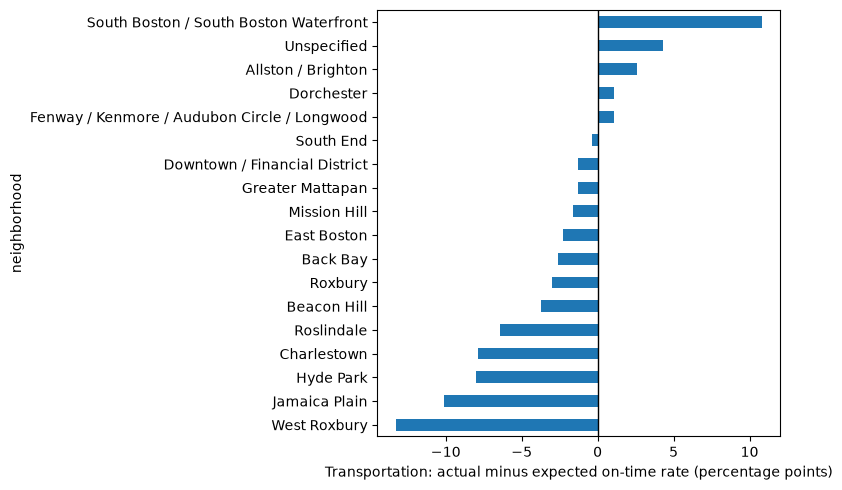

In [17]:
eq = equity.neighborhood_equity()
display(equity.equity_summary(eq))
btdt = eq[(eq.department == "BTDT") & ~eq.small_sample].sort_values("gap_pct_points")
ax = btdt.plot.barh(x="neighborhood", y="gap_pct_points", legend=False, figsize=(8, 5))
ax.axvline(0, color="black", lw=1); ax.set_xlabel("Transportation: actual minus expected on-time rate (percentage points)")
plt.tight_layout(); plt.show()

**Findings.**
* **Public Works, Parks, and Inspectional Services:** every neighborhood is within ±4.4 points of its expected rate.
* **Transportation varies most:** West Roxbury is 13.3 points below its expected rate, and South Boston / South Boston Waterfront 10.8 points above.
* Reporting channels and employee-generated requests may differ by neighborhood, and synthetic 2025 requests carry no neighborhood, so equity is analysed on historical data only.

## 9. Run manifest

Everything needed to check this run: input checksums, parameters, seeds, model and prompt versions, mode, and package versions. It is saved as one JSON file per run in `outputs/manifests/`, which git ignores. The committed `reference_run_all.json` describes the committed outputs.

In [18]:
m = manifest.build_manifest(MODE, outputs=[], extra={"run": "demo.ipynb"})
path = manifest.write_manifest(m)
print("Run manifest saved to outputs/manifests/" + path.name)
print({k: m[k] for k in ("created_utc", "mode", "training_cutoff", "seeds", "model")})
print(len(m["inputs"]), "input files checksummed; git commit:", m["environment"]["git_commit"])

Run manifest saved to outputs/manifests/run_20261023T140423Z.json
{'created_utc': '2026-10-23T14:04:23+00:00', 'mode': 'offline', 'training_cutoff': '2024-12-31', 'seeds': {'planning': 20250101, 'evaluation': 20251231}, 'model': {'provider': 'openai', 'id': 'gpt-6.1-sol', 'reasoning_effort': 'low', 'seed': 5250, 'prompt_version': 'classify-v2', 'alias_prompt_version': 'aliases-v2', 'catalog_version': 'catalog-v2'}}
19 input files checksummed; git commit: 33824dc3fb1533a640cb0e45d41cb026e6e3d6b3-dirty


## Notes and limits

* **Challenge model.** Capacity, cost, starting crews, and penalties are the project page's assumptions, not Boston's real operations. The 21-service-day calendar is synthetic.
* **Evaluation workloads are synthetic.** The plan is scored on a separately seeded synthetic workload, not on real unseen 2025 requests.
* **Catalog review.** The team reviewed every mapping, alias set, and evaluation example (2026-10-27): 124 department mappings and 83 exact queues are approved, and 8 internal or undefined types are rejected and go to triage. An approval means a mapping is consistent with the 2023 to 2024 routing data, not that the city's service eligibility was verified.
* **Remaining catalog exceptions.** Wording for 10 types is still provisional and is still used by retrieval. Scooters and mopeds are described only under Abandoned Vehicles, although historical titles put them under Abandoned Bicycle too. Details are in `docs/architecture.md`, section 11.5.
* **Evaluation limits.** The dev and test messages were written within the same build as the catalog wording, six labels were corrected in the review, and the agreement rule was prompted by test example t13 (`docs/architecture.md`, section 11.4). The scores are a demonstration evaluation, not a measure of performance on new residents' messages. Staffing results come from one planning seed and one evaluation seed.
* **Parks seasonal target.** The 93% floor is a policy choice (no worse than 2024), backed by the cost-versus-service frontier above. See `docs/decisions.md`.
* **Hiring looks at volume, not deadlines.** The hiring rule counts every arriving request, including Parks requests with year-long deadlines. Where the seasonal rule leaves a backlog, it can still order permanent crews in October, as the rejected cost-only rule showed.
* **Synthetic workload contents.** No-target requests use capacity but carry no penalty, as a labelled assumption. Synthetic requests have no neighborhood.
* **Frozen plan only.** Sensitivity replays the frozen plan. Reactive re-planning and a 2025 holdout were not built.
* **Authorship and AI use.** See the Authorship section of the README.